![Logo Javeriana](https://images.seeklogo.com/logo-png/11/1/pontificia-universidad-javeriana-logo-png_seeklogo-110703.png)

# Clasificación de ingresos anuales con Apache Spark

**Estudiante** Gabriel Jaramillo Cuberos  
**ID** 20529022  
**Asignatura** Procesamiento de Datos (1255)  
**Cuaderno** `JaramilloSalario_1255.ipynb`

## Contexto

Census Income, también conocido como Adult, contiene registros extraídos de una base censal de 1994. La fuente reporta 48.842 observaciones y 14 atributos de entrada. El problema consiste en clasificar cada observación según si su ingreso anual supera los 50.000 dólares.

Se trabaja con dos clases. La clase `1` corresponde a ingresos mayores de 50.000 dólares; la clase `0` corresponde a ingresos de hasta 50.000 dólares, incluido ese valor.

## Objetivo general

Comparar cinco clasificadores de MLlib para identificar los registros con ingresos anuales superiores a 50.000 dólares, utilizando PySpark en el clúster del equipo.

## Objetivos específicos

- Examinar la estructura de los archivos, los valores faltantes y la distribución de la variable objetivo.
- Documentar la selección de atributos y las transformaciones necesarias para entrenar los modelos.
- Entrenar cinco clasificadores sobre una preparación común y escoger uno mediante validación.
- Comparar los modelos sobre el archivo oficial de prueba e interpretar los errores de ambas clases.

## Desarrollo

El taller sigue las etapas de comprensión del problema, conocimiento y preparación de datos, modelado y evaluación. Se utiliza `adult.data` para entrenamiento y validación. Se reserva `adult.test` para la evaluación final.

**Fuente** Kohavi, R. (1996). [Census Income](https://archive.ics.uci.edu/dataset/20/census+income). UCI Machine Learning Repository.

## Se inicia la sesion Spark

In [1]:
from Utils import proyecto as p

# Utils aplica el máster y los recursos configurados para el proyecto.
spark = p.iniciar_spark("SalarioBigData_Jaramillo")

print("Master:", spark.sparkContext.master)

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer, OneHotEncoder, StandardScaler, VectorAssembler
)
from pyspark.ml.classification import (
    LogisticRegression, DecisionTreeClassifier, RandomForestClassifier,
    LinearSVC, MultilayerPerceptronClassifier
)
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Python: 3.11.13 | PySpark: 4.2.0 | Spark: 4.2.0
Ejecutable: /home/estudiante/jupyter-spark-env/bin/python
Aplicación: app-20261123121801-0115 | Máximo de núcleos: 2
Los recursos físicos del cluster deben documentarse desde la interfaz del master.
Master: spark://10.43.97.76:8888


## Conocimiento de los datos

Cada fila representa un registro censal. Los dos archivos de datos están separados por comas y carecen de encabezados. Por eso se asignan los nombres de las columnas en el orden publicado por UCI.

| Variable | Tipo | Qué representa |
|---|---|---|
| `age` | Numérica | Edad en años. |
| `workclass` | Categórica | Clase de empleo. |
| `fnlwgt` | Numérica | Peso final del registro en la fuente censal. |
| `education` | Categórica | Nombre del nivel educativo. |
| `education_num` | Numérica ordinal | Código ordenado del nivel educativo. |
| `marital_status` | Categórica | Estado civil registrado. |
| `occupation` | Categórica | Ocupación. |
| `relationship` | Categórica | Relación dentro del hogar. |
| `race` | Categórica | Categoría racial registrada en la fuente. |
| `sex` | Categórica | Sexo registrado en la fuente. |
| `capital_gain` | Numérica | Ganancias de capital registradas. |
| `capital_loss` | Numérica | Pérdidas de capital registradas. |
| `hours_per_week` | Numérica | Horas de trabajo semanales. |
| `native_country` | Categórica | País de origen registrado. |
| `income` | Objetivo | Clase de ingreso anual, `<=50K` o `>50K`. |

La lectura se hace con la sesión Spark iniciada con los recursos del cluster del equipo. La función `leer_csv` de `Utils` espera encabezados, así que para los archivos originales de Adult se define un lector con esquema explícito. También se omite la línea introductoria de `adult.test`, que empieza con `|`.

In [2]:
RUTA_DATOS = "file:///opt/cluster/TallerCenso/Documentos"

COLUMNAS = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country",
    "income"
]

# Leer como texto para poder limpiar las marcas de faltantes primero.
ESQUEMA = ", ".join(f"{c} STRING" for c in COLUMNAS)

def leer_adult(archivo):
    ruta = f"{RUTA_DATOS.rstrip('/')}/{archivo}"
    return (
        spark.read.schema(ESQUEMA)
        .option("header", "false")
        .option("comment", "|")
        .option("ignoreLeadingWhiteSpace", "true")
        .option("ignoreTrailingWhiteSpace", "true")
        .option("mode", "FAILFAST")
        .csv(ruta)
    )

adult_data = leer_adult("adult.data")
adult_test = leer_adult("adult.test")

print("Carpeta de entrada:", RUTA_DATOS)
adult_data.printSchema()
adult_data.show(5, truncate=False)

Carpeta de entrada: file:///opt/cluster/TallerCenso/Documentos
root
 |-- age: string (nullable = true)
 |-- workclass: string (nullable = true)
 |-- fnlwgt: string (nullable = true)
 |-- education: string (nullable = true)
 |-- education_num: string (nullable = true)
 |-- marital_status: string (nullable = true)
 |-- occupation: string (nullable = true)
 |-- relationship: string (nullable = true)
 |-- race: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- capital_gain: string (nullable = true)
 |-- capital_loss: string (nullable = true)
 |-- hours_per_week: string (nullable = true)
 |-- native_country: string (nullable = true)
 |-- income: string (nullable = true)



[Stage 0:>                                                          (0 + 1) / 1]

+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
|age|workclass       |fnlwgt|education|education_num|marital_status    |occupation       |relationship |race |sex   |capital_gain|capital_loss|hours_per_week|native_country|income|
+---+----------------+------+---------+-------------+------------------+-----------------+-------------+-----+------+------------+------------+--------------+--------------+------+
|39 |State-gov       |77516 |Bachelors|13           |Never-married     |Adm-clerical     |Not-in-family|White|Male  |2174        |0           |40            |United-States |<=50K |
|50 |Self-emp-not-inc|83311 |Bachelors|13           |Married-civ-spouse|Exec-managerial  |Husband      |White|Male  |0           |0           |13            |United-States |<=50K |
|38 |Private         |215646|HS-grad  |9            |Divorced          |Handlers-cleaners|Not-i

## Preparación de datos

Se reutilizan `p.texto` y `p.numero` para limpiar texto y convertir atributos numéricos. Se traduce `?` a faltante. En la variable objetivo se retira el punto que aparece al final de las etiquetas de `adult.test` y se codifican las clases en `label`.

Se revisan los faltantes y se cuentan las filas idénticas. Las coincidencias se conservan porque el archivo carece de un identificador de persona. Dos filas iguales pueden corresponder a personas distintas.

Los predictores seleccionados son edad, nivel educativo ordenado, ganancias y pérdidas de capital, horas semanales, clase de empleo, estado civil, ocupación y relación dentro del hogar.

- Se conserva `education_num` como representación del nivel educativo.
- `fnlwgt` es un peso censal. Las métricas de este ejercicio se calculan por registro, sin ponderación.
- Se excluyen `race`, `sex` y `native_country` como predictores directos. La evaluación global deja pendiente medir el desempeño por subgrupos.
- Los faltantes categóricos se representan con `SIN_DATO` para conservar las filas e identificar la ausencia de información.

Se divide `adult.data` en aproximadamente 80 % para entrenamiento y 20 % para validación. La división usa un hash reproducible de los predictores, de modo que filas con las mismas entradas queden juntas dentro de `adult.data`. `adult.test` conserva la separación de UCI.

In [3]:
SEMILLA = 1255

numericas = [
    "age", "education_num", "capital_gain", "capital_loss", "hours_per_week"
]
categoricas = [
    "workclass", "marital_status", "occupation", "relationship"
]

def limpiar_adult(df):
    # p.texto quita espacios y reconoce textos vacíos como faltantes.
    # Aquí también se convierte el marcador ? propio de Adult.
    limpias = []
    for c in COLUMNAS:
        valor = p.texto(c)
        limpias.append(F.when(valor != "?", valor).alias(c))

    df = df.select(*limpias)

    for c in numericas + ["fnlwgt"]:
        df = df.withColumn(c, p.numero(c))

    # Ejemplo: >50K. pasa a >50K.
    df = df.withColumn("income", F.regexp_replace("income", r"\.$", ""))

    return df.withColumn(
        "label",
        F.when(F.col("income") == ">50K", 1.0)
         .when(F.col("income") == "<=50K", 0.0)
    )

desarrollo = limpiar_adult(adult_data).cache()
prueba = limpiar_adult(adult_test).cache()

n_desarrollo = desarrollo.count()
n_prueba = prueba.count()

print(f"adult.data: {n_desarrollo} | adult.test: {n_prueba}")
print(f"Total leído: {n_desarrollo + n_prueba} | Total reportado por UCI: 48842")

for nombre, df in [("adult.data", desarrollo), ("adult.test", prueba)]:
    if df.filter(F.col("label").isNull()).limit(1).count():
        raise ValueError(f"{nombre} contiene una etiqueta diferente de <=50K o >50K.")

    if df.select(*numericas).na.drop().count() != df.count():
        raise ValueError(f"{nombre} contiene atributos numéricos faltantes o inválidos.")

print("Reporte de calidad de adult.data")
p.tabla(p.calidad(desarrollo.select(*COLUMNAS)))

print(
    "Filas idénticas adicionales en adult.data:",
    n_desarrollo - desarrollo.distinct().count()
)

adult.data: 32561 | adult.test: 16281
Total leído: 48842 | Total reportado por UCI: 48842
Reporte de calidad de adult.data


columna,faltantes,total,porcentaje
age,0,32561,0.0
workclass,1836,32561,5.639
fnlwgt,0,32561,0.0
education,0,32561,0.0
education_num,0,32561,0.0
marital_status,0,32561,0.0
occupation,1843,32561,5.66
relationship,0,32561,0.0
race,0,32561,0.0
sex,0,32561,0.0


[Stage 33:>                                                         (0 + 1) / 1]

Filas idénticas adicionales en adult.data: 24


In [4]:
def seleccionar(df):
    return (
        df.select(*numericas, *categoricas, "label")
        .fillna("SIN_DATO", subset=categoricas)
    )

# Asignar uno de 100 grupos usando los predictores y la semilla.
predictores = [F.col(c) for c in numericas + categoricas]
grupo = F.pmod(F.xxhash64(*predictores, F.lit(SEMILLA)), F.lit(100))
base = seleccionar(desarrollo).withColumn("_grupo", grupo)

train_raw = base.filter(F.col("_grupo") < 80).drop("_grupo")
val_raw = base.filter(F.col("_grupo") >= 80).drop("_grupo")
test_raw = seleccionar(prueba)

# Comparar la representación de las clases en los dos conjuntos.
for nombre, df in [("Entrenamiento", train_raw), ("Validación", val_raw)]:
    clases = p.filas(df.groupBy("label").count().orderBy("label"))

    if {fila["label"] for fila in clases} != {0.0, 1.0}:
        raise ValueError(f"{nombre} debe contener las dos clases.")

    total = sum(fila["count"] for fila in clases)
    print(nombre)
    p.tabla([
        {
            "clase": ">50K" if fila["label"] == 1 else "<=50K",
            "registros": fila["count"],
            "porcentaje": round(100 * fila["count"] / total, 2)
        }
        for fila in clases
    ])

# Cada porcentaje usa como denominador los registros de esa clase de empleo.
print("Proporción de ingresos >50K por clase de empleo en entrenamiento")
por_trabajo = (
    train_raw.groupBy("workclass")
    .agg(
        F.count("*").alias("registros"),
        F.sum("label").cast("long").alias("positivos"),
        F.round(100 * F.avg("label"), 2).alias("pct_mas_50k")
    )
    .orderBy(F.desc("registros"))
)
p.tabla(p.filas(por_trabajo))

print("Promedios por clase de ingreso en entrenamiento")
medias = (
    train_raw.groupBy("label")
    .agg(
        F.round(F.avg("age"), 2).alias("edad_media"),
        F.round(F.avg("hours_per_week"), 2).alias("horas_semanales_media"),
        F.round(F.avg("education_num"), 2).alias("nivel_educativo_medio")
    )
    .orderBy("label")
)
p.tabla(p.filas(medias))

Entrenamiento


clase,registros,porcentaje
<=50K,19708,76.05
>50K,6205,23.95


Validación


clase,registros,porcentaje
<=50K,5012,75.39
>50K,1636,24.61


Proporción de ingresos >50K por clase de empleo en entrenamiento


workclass,registros,positivos,pct_mas_50k
Private,18058,3937,21.8
Self-emp-not-inc,2011,555,27.6
Local-gov,1670,476,28.5
SIN_DATO,1451,150,10.34
State-gov,1023,280,27.37
Self-emp-inc,925,521,56.32
Federal-gov,757,286,37.78
Without-pay,11,0,0.0
Never-worked,7,0,0.0


Promedios por clase de ingreso en entrenamiento


label,edad_media,horas_semanales_media,nivel_educativo_medio
0.0,36.83,38.72,9.59
1.0,44.26,45.55,11.6


## Lectura de la exploración

La distribución de la etiqueta muestra cuántos registros corresponden a cada clase. Esto permite anticipar cuánto podría acertar un clasificador que siempre predice la clase mayoritaria y entender por qué conviene revisar la sensibilidad de la clase `>50K`.

La tabla por clase de empleo compara el porcentaje de ingresos `>50K` dentro de cada grupo. El número de registros acompaña cada porcentaje porque una categoría pequeña puede cambiar mucho con unos pocos casos. Las medias de edad, horas y nivel educativo describen diferencias entre las clases registradas. La exploración se concentra en entrenamiento.

## Construcción de características

Se usa `StringIndexer` para convertir las categorías de texto en índices y `OneHotEncoder` para representarlas mediante indicadores. Las variables continuas se estandarizan con `StandardScaler`. `VectorAssembler` combina esos componentes en el vector `features` que reciben los cinco modelos.

El Pipeline aprende las categorías y las escalas exclusivamente con entrenamiento. Después transforma validación y prueba con esos mismos parámetros.

In [5]:
idx = [c + "_idx" for c in categoricas]
ohe = [c + "_ohe" for c in categoricas]

preparacion = Pipeline(stages=[
    StringIndexer(
        inputCols=categoricas,
        outputCols=idx,
        handleInvalid="keep"
    ),
    OneHotEncoder(
        inputCols=idx,
        outputCols=ohe,
        dropLast=False
    ),
    VectorAssembler(
        inputCols=numericas,
        outputCol="vector_numerico"
    ),
    StandardScaler(
        inputCol="vector_numerico",
        outputCol="numericas_escaladas",
        withMean=True,
        withStd=True
    ),
    VectorAssembler(
        inputCols=["numericas_escaladas"] + ohe,
        outputCol="features"
    )
])

ajustada = preparacion.fit(train_raw)

train = ajustada.transform(train_raw).select("label", "features").cache()
val = ajustada.transform(val_raw).select("label", "features").cache()

# El perceptrón necesita conocer el tamaño real del vector de entrada.
n_features = train.first()["features"].size
print("Componentes de features:", n_features)

[Stage 60:>                                                         (0 + 1) / 1]

Componentes de features: 46


## Selección de los modelos

| Modelo de MLlib | Justificación |
|---|---|
| Regresión logística | Clasificador lineal de referencia para una respuesta binaria. |
| Árbol de decisión | Aprende reglas a partir de cortes y combinaciones de atributos. |
| Bosque aleatorio | Combina varios árboles y permite comparar ese conjunto con un árbol individual. |
| SVM lineal | Incluye otro método lineal que aprende a separar las clases mediante un margen. |
| Perceptrón multicapa | Red neuronal pequeña capaz de representar relaciones no lineales. |

Se entrena una configuración de cada modelo. Se selecciona el mayor **F1 de la clase `>50K`** en validación. La PR-AUC sirve para desempatar.

La exactitud mide el porcentaje total de aciertos. La sensibilidad indica qué fracción de los positivos reales se identifica. La precisión positiva indica qué fracción de las predicciones positivas es correcta. F1 combina sensibilidad y precisión. Cuando un modelo predice cero positivos, se reporta precisión positiva igual a cero por convenio.

La matriz de confusión muestra los conteos detrás de esas métricas. La ROC-AUC y la PR-AUC resumen cómo ordena el modelo los registros mediante sus puntuaciones a través de distintos umbrales. La referencia para la exactitud es un clasificador que siempre predice `<=50K`.

In [6]:
comun = {"featuresCol": "features", "labelCol": "label"}

algoritmos = {
    "Regresión logística": LogisticRegression(
        **comun, maxIter=60, regParam=0.01
    ),
    "Árbol de decisión": DecisionTreeClassifier(
        **comun, maxDepth=6, minInstancesPerNode=10, seed=SEMILLA
    ),
    "Bosque aleatorio": RandomForestClassifier(
        **comun, numTrees=30, maxDepth=7, seed=SEMILLA
    ),
    "SVM lineal": LinearSVC(
        **comun, maxIter=60, regParam=0.01
    ),
    "Perceptrón multicapa": MultilayerPerceptronClassifier(
        **comun,
        layers=[n_features, 16, 2],
        maxIter=80,
        blockSize=128,
        seed=SEMILLA
    )
}

evaluador = BinaryClassificationEvaluator(
    labelCol="label", rawPredictionCol="score", numBins=0
)

def evaluar(nombre, modelo, datos):
    pred = modelo.transform(datos)

    # SVM entrega un margen; los demás entregan probability.
    columna_score = "probability" if "probability" in pred.columns else "rawPrediction"
    pred = pred.select(
        "label", "prediction",
        vector_to_array(F.col(columna_score))[1].alias("score")
    ).cache()

    try:
        # Solo se traen al cuaderno los cuatro conteos de la matriz.
        conteos = {
            (int(fila["label"]), int(fila["prediction"])): fila["count"]
            for fila in p.filas(pred.groupBy("label", "prediction").count())
        }

        vn = conteos.get((0, 0), 0)
        fp = conteos.get((0, 1), 0)
        fn = conteos.get((1, 0), 0)
        vp = conteos.get((1, 1), 0)

        return {
            "modelo": nombre,
            "exactitud": (vn + vp) / (vn + fp + fn + vp),
            "precision_1": vp / (vp + fp) if vp + fp else 0.0,
            "sensibilidad_1": vp / (vp + fn) if vp + fn else 0.0,
            "f1_1": 2 * vp / (2 * vp + fp + fn) if 2 * vp + fp + fn else 0.0,
            "pr_auc": evaluador.evaluate(
                pred, {evaluador.metricName: "areaUnderPR"}
            ),
            "roc_auc": evaluador.evaluate(
                pred, {evaluador.metricName: "areaUnderROC"}
            ),
            "VN": vn, "FP": fp, "FN": fn, "VP": vp
        }
    finally:
        pred.unpersist()

In [7]:
modelos = {}
metricas_val = []

for nombre, algoritmo in algoritmos.items():
    print("Entrenando", nombre)
    modelos[nombre] = algoritmo.fit(train)
    metricas_val.append(evaluar(nombre, modelos[nombre], val))

tabla_val = (
    pd.DataFrame(metricas_val)
    .set_index("modelo")
    .sort_values(["f1_1", "pr_auc"], ascending=False)
)

elegido = tabla_val.index[0]

display(tabla_val.round(4))
print("Seleccionado en validación:", elegido)

Entrenando Regresión logística


netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
                                                                                

Entrenando Árbol de decisión
Entrenando Bosque aleatorio
Entrenando SVM lineal
Entrenando Perceptrón multicapa


,exactitud,precision_1,sensibilidad_1,f1_1,pr_auc,roc_auc,VN,FP,FN,VP
modelo,,,,,,,,,,
Perceptrón multicapa,0.8597,0.7575,0.6320,0.6891,0.7952,0.9140,4681,331,602,1034
SVM lineal,0.8473,0.7474,0.5733,0.6489,0.7564,0.8987,4695,317,698,938
Regresión logística,0.8472,0.7480,0.5715,0.6480,0.7498,0.8992,4697,315,701,935
Bosque aleatorio,0.8448,0.7854,0.5079,0.6169,0.7617,0.8951,4785,227,805,831
Árbol de decisión,0.8412,0.7772,0.4969,0.6063,0.7473,0.8764,4779,233,823,813


Seleccionado en validación: Perceptrón multicapa


## Prueba, gráfica y matriz de confusión

Se realizan las pruebas correspondientes a los modelos de ML, junto a la matriz de confusión.

,exactitud,precision_1,sensibilidad_1,f1_1,pr_auc,roc_auc,VN,FP,FN,VP
modelo,,,,,,,,,,
Perceptrón multicapa,0.8596,0.7413,0.6230,0.6770,0.7857,0.9128,11599,836,1450,2396
SVM lineal,0.8514,0.7399,0.5718,0.6451,0.7545,0.9011,11662,773,1647,2199
Regresión logística,0.8495,0.7356,0.5663,0.6399,0.7496,0.9025,11652,783,1668,2178
Bosque aleatorio,0.8471,0.7775,0.4943,0.6044,0.7575,0.8996,11891,544,1945,1901
Árbol de decisión,0.8472,0.7810,0.4906,0.6027,0.7463,0.8801,11906,529,1959,1887


Referencia siempre <=50K: 76.38% de exactitud y 0 % de sensibilidad


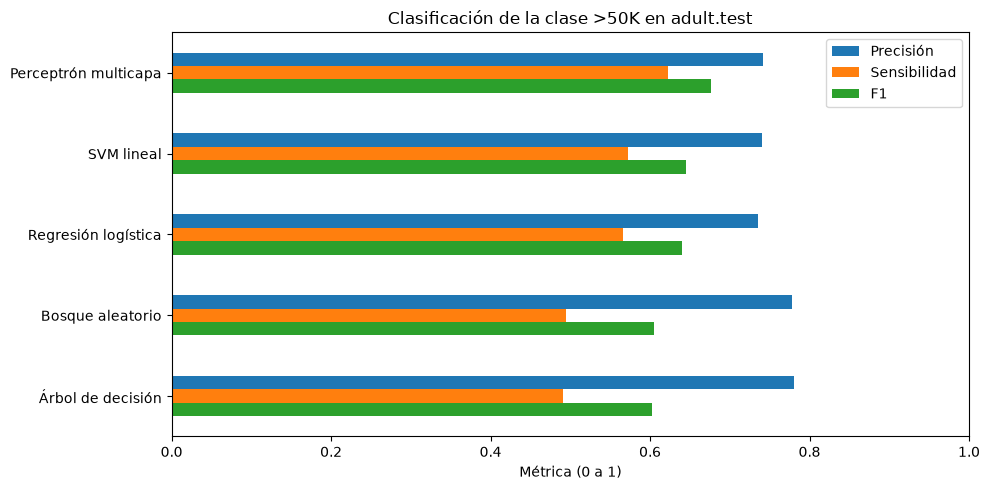

Matriz de confusión de Perceptrón multicapa


,Predicción <=50K,Predicción >50K
Real <=50K,11599,836
Real >50K,1450,2396


In [8]:
test = ajustada.transform(test_raw).select("label", "features").cache()

clases_test = {
    int(fila["label"]): fila["count"]
    for fila in p.filas(test.groupBy("label").count())
}

if set(clases_test) != {0, 1}:
    raise ValueError("adult.test debe contener las dos clases.")

positivos_test = clases_test[1]
exactitud_base = clases_test[0] / sum(clases_test.values())

# Se evalúan los cinco modelos que ya quedaron entrenados.
tabla_test = pd.DataFrame([
    evaluar(nombre, modelos[nombre], test)
    for nombre in tabla_val.index
]).set_index("modelo")

display(tabla_test.round(4))
print(
    f"Referencia siempre <=50K: {exactitud_base:.2%} de exactitud "
    "y 0 % de sensibilidad"
)

grafica = tabla_test[["precision_1", "sensibilidad_1", "f1_1"]].rename(
    columns={
        "precision_1": "Precisión",
        "sensibilidad_1": "Sensibilidad",
        "f1_1": "F1"
    }
)

ax = grafica.plot.barh(figsize=(10, 5), xlim=(0, 1))
ax.set(
    title="Clasificación de la clase >50K en adult.test",
    xlabel="Métrica (0 a 1)",
    ylabel=""
)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Matriz del modelo seleccionado en validación.
r = tabla_test.loc[elegido]
print("Matriz de confusión de", elegido)

display(pd.DataFrame(
    [[int(r["VN"]), int(r["FP"])], [int(r["FN"]), int(r["VP"])]],
    index=["Real <=50K", "Real >50K"],
    columns=["Predicción <=50K", "Predicción >50K"]
))

## Análisis de resultados

### Exploración de los datos

Se leyeron 48.842 registros. De los 32.561 registros de `adult.data`, se usaron 25.913 para entrenamiento y 6.648 para validación. La proporción de la clase `>50K` fue del 23,95 % en entrenamiento y del 24,61 % en validación. La evaluación final se realizó sobre los 16.281 registros de `adult.test`.

En entrenamiento, los registros de la clase `>50K` tenían en promedio 44,26 años y 45,55 horas de trabajo semanal, frente a 36,83 años y 38,72 horas en la clase `<=50K`. También presentaron un promedio más alto en el código de nivel educativo. Estas diferencias describen la muestra y pueden orientar la selección de atributos, aunque por sí solas no establecen relaciones de causa y efecto.

La comparación por clase de empleo muestra la importancia de usar denominadores. El sector privado concentró 3.937 registros con ingresos `>50K` de un total de 18.058 (21,80 %). Entre los trabajadores por cuenta propia con empresa constituida (`Self-emp-inc`), hubo menos registros positivos en total, 521, pero representaron el 56,32 % de los 925 registros de esa categoría.

### Comparación de modelos

El perceptrón multicapa se seleccionó por su **F1 positivo de 0,6891 en validación**. Con esa decisión ya tomada, se evaluaron los cinco modelos en la prueba oficial.

| Modelo | Exactitud | Precisión `>50K` | Sensibilidad `>50K` | F1 `>50K` | PR-AUC |
|---|---:|---:|---:|---:|---:|
| **Perceptrón multicapa** | **85,96 %** | 74,13 % | **62,30 %** | **0,6770** | **0,7857** |
| SVM lineal | 85,14 % | 73,99 % | 57,18 % | 0,6451 | 0,7545 |
| Regresión logística | 84,95 % | 73,56 % | 56,63 % | 0,6399 | 0,7496 |
| Bosque aleatorio | 84,71 % | 77,75 % | 49,43 % | 0,6044 | 0,7575 |
| Árbol de decisión | 84,72 % | **78,10 %** | 49,06 % | 0,6027 | 0,7463 |

El perceptrón obtuvo el mayor F1 en prueba y la mayor sensibilidad para la clase `>50K`. El árbol de decisión tuvo la mayor precisión positiva, pero identificó menos de la mitad de los positivos reales. En términos de errores, el árbol generó **529 falsos positivos** y omitió **1.959 positivos**, mientras que el perceptrón generó **836 falsos positivos** y omitió **1.450 positivos**. El perceptrón recuperó más casos de la clase de interés a cambio de más falsas alarmas.

### Matriz de confusión del modelo seleccionado

De los **3.846 registros** que realmente superaban los 50.000 dólares, el perceptrón identificó **2.396** y omitió **1.450**. De ahí sale la sensibilidad del **62,30 %**. Por otro lado, el modelo predijo `>50K` en **3.232 registros**, de los cuales 2.396 pertenecían a esa clase. De ahí sale la precisión positiva del **74,13 %**.

La referencia que siempre asigna `<=50K` obtuvo una exactitud del **76,38 %** y omitió todos los casos de la clase `>50K`. El perceptrón alcanzó el **85,96 %** de exactitud, una mejora de **9,58 puntos porcentuales** frente a esa referencia. La cantidad de falsos negativos muestra cuánto margen de mejora queda, incluso con esa diferencia en exactitud.

## Conclusiones

1. Se entrenaron y evaluaron cinco clasificadores de MLlib con PySpark en el clúster del grupo. Los modelos utilizaron la misma preparación de características y se compararon sobre los mismos 16.281 registros de la prueba oficial.

2. El **perceptrón multicapa** fue el modelo elegido según el F1 de la clase `>50K` en validación. En prueba obtuvo un **F1 de 0,6770**, una **exactitud del 85,96 %** y una **sensibilidad del 62,30 %**. Estos resultados respaldan su elección dentro de las configuraciones evaluadas.

3. La matriz de confusión permitió identificar la principal limitación del modelo. Aunque acertó la clase de 2.396 registros con ingresos superiores a 50.000 dólares, omitió 1.450. La comparación con el árbol de decisión mostró que mejorar la detección puede aumentar los falsos positivos. El F1 permitió considerar ambos aspectos al seleccionar el modelo.

4. El resultado corresponde a la clasificación de un umbral de ingresos en una muestra censal histórica. La evaluación mide el desempeño general sobre la prueba oficial de UCI. Para evaluar su aplicación a datos actuales o su desempeño en distintos grupos de población, harían falta pruebas específicas.

## Cierre de la sesión

Se cierra la sesión Spark para liberar recursos.

In [9]:
spark.stop()